# A4-Q3: Convolutional Autoencoders

## Preliminaries

In [20]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

In [21]:
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)

from torchvision.datasets import MNIST
from torchvision import transforms
ds = MNIST("./files", train=True, download=True, transform=transforms.ToTensor())
print("Sample shape:", ds[0][0].shape)


torch: 2.6.0+cu124
torchvision: 0.21.0+cu124
Sample shape: torch.Size([1, 28, 28])


In [22]:
# In case you are fortunate enough to have access to a GPU...
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Dataset: MNIST

In [23]:
# You can change img_size to 14 if you want to use smaller (14x14) images.
img_size = 28
ds_full = torchvision.datasets.MNIST('./files/', train=True, download=True,
                            transform=torchvision.transforms.Compose([
                            torchvision.transforms.Resize((img_size,img_size)),
                            torchvision.transforms.ToTensor(),
                            ]))

In [24]:
ds = torch.utils.data.Subset(ds_full, range(1024))

In [25]:
def Draw(x):
    with torch.no_grad():
        plt.imshow(x.squeeze().detach().numpy(), cmap='gray')
        plt.axis('off')

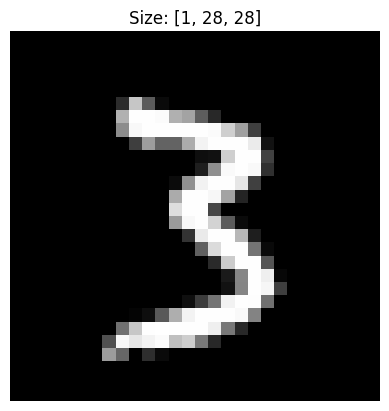

In [26]:
with torch.no_grad():
    x,t = ds.__getitem__(130)
    Draw(x)
    plt.title(f'Size: {list(x.size())}')
plt.show()

## Create some `DataLoader`s

In [27]:
# Batched, for training
batch_size_train = 8
train_dl = torch.utils.data.DataLoader(ds, batch_size=batch_size_train, shuffle=True)

In [28]:
# A single batch, for plotting
train_all = torch.utils.data.DataLoader(ds, batch_size=1024, shuffle=False)

# A. Complete the `ConvAE` class

In [29]:
class ConvAE(nn.Module):
    '''
     net = ConvAE(img_size=28, embedding_dim=3)
     
     Create a convolutional autoencoder for imput images of size (img_size x img_size),
     with an embedding (latent) layer of (embedding_dim) neurons.
     
     Inputs:
       img_size       size of input images, [1, img_size, img_size]
       embedding_dim  number of nodes in embedding (latent) layer
       
     Usage:
       net = ConvAE()
       y = net(x)
       h = net.encode(x)  # returns latent vectors
    '''
    def __init__(self, img_size=28, embedding_dim=3):
        self.img_size = img_size
        self.embedding_dim = embedding_dim
        self.losses = []
        super().__init__()
        
        #===== YOUR CODE HERE =====
        
        # (B,1,H,W) -> (B,16,H/2,W/2) -> (B,32,H/4,W/4) -> (B,64,H/4,W/4)
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
        )

        # Figure out flattened conv feature size dynamically
        with torch.no_grad():
            _dummy = torch.zeros(1, 1, img_size, img_size)
            _feat = self.enc_conv(_dummy)
            self._enc_shape = _feat.shape[1:]
            self._enc_flat  = int(_feat.numel())

        # Dense → latent
        self.enc_fc1 = nn.Linear(self._enc_flat, 128)
        self.enc_mu  = nn.Linear(128, embedding_dim)

        # Decoder
        self.dec_fc1 = nn.Linear(embedding_dim, 128)
        self.dec_fc2 = nn.Linear(128, self._enc_flat)

        C, Hc, Wc = self._enc_shape
        self.unflatten = nn.Unflatten(1, (C, Hc, Wc))

        # (B,1,img_size,img_size)
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=1, padding=1), #(B,32,Hc,Wc)
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),#(B,16,2Hc,2Wc)
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(16, 1,  kernel_size=4, stride=2, padding=1), #(B,1,4Hc,4Wc)
            nn.Sigmoid(),
        )

        
    def encode(self, x):
        #===== YOUR CODE HERE =====
        z = self.enc_conv(x)
        z = z.view(z.size(0), -1)
        z = nn.functional.relu(self.enc_fc1(z))
        h = torch.tanh(self.enc_mu(z))
        return h
    
    
    def decode(self, x):
        #===== YOUR CODE HERE =====
        z = nn.functional.relu(self.dec_fc1(x))
        z = nn.functional.relu(self.dec_fc2(z))
        z = self.unflatten(z)
        y = self.dec_conv(z)
        return y
  

    def forward(self, x):
        #===== YOUR CODE HERE =====
        h = self.encode(x)
        y = self.decode(h)
        return y


# B. Create and train the network

In [30]:
print("Using device:", device)
net = ConvAE(img_size=img_size, embedding_dim=3).to(device)


Using device: cuda


In [ ]:
# Train it
epochs = 128
batch_size = 32

lr = 1e-3
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-5)

# Dataloader
train_dl = torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=True, pin_memory=True)

# ----- Training loop -----
for epoch in range(epochs):
    net.train()
    running_loss = 0.0
    for x, _ in tqdm(train_dl, desc=f"Epoch {epoch+1}/{epochs}", leave=False):
        x = x.to(device)

        # forward
        y = net(x)
        loss = criterion(y, x)

        # backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)

    epoch_loss = running_loss / len(train_dl.dataset)
    net.losses.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{epochs}]  Loss: {epoch_loss:.6f}")

print("Training complete.")

Epoch [1/128]  Loss: 0.130920


Epoch [2/128]  Loss: 0.070639


Epoch [3/128]  Loss: 0.066684


Epoch [4/128]  Loss: 0.066255


Epoch [5/128]  Loss: 0.066111


Epoch [6/128]  Loss: 0.066039


... (118 outputs left out)

Epoch [125/128]  Loss: 0.027455


Epoch [126/128]  Loss: 0.027360


Epoch [127/128]  Loss: 0.027315


Epoch [128/128]  Loss: 0.027524
Training complete.


In [32]:
# Uncomment the following line if you want to save your network.
#torch.save(net.to('cpu'), 'my_ConvAE.pt')
# The corresponding code to reload the network is below.
#net = torch.load('my_ConvAE.pt')
# Remember to send it to the GPU, if you're using one.
#net.to(device)


# pytorch 2.6 changes, so use state_dict() to save and load models
net_cpu = net.to('cpu')
torch.save(net_cpu.state_dict(), 'my_ConvAE.pt')
net.to(device)

#loading the model
net = ConvAE(img_size=img_size, embedding_dim=3).to(device)
state = torch.load("my_ConvAE.pt", map_location=device)
net.load_state_dict(state, strict=True)
net.to(device)
net.eval()


ConvAE(
  (enc_conv): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
  )
  (enc_fc1): Linear(in_features=3136, out_features=128, bias=True)
  (enc_mu): Linear(in_features=128, out_features=3, bias=True)
  (dec_fc1): Linear(in_features=3, out_features=128, bias=True)
  (dec_fc2): Linear(in_features=128, out_features=3136, bias=True)
  (unflatten): Unflatten(dim=1, unflattened_size=(64, 7, 7))
  (dec_conv): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(16, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))

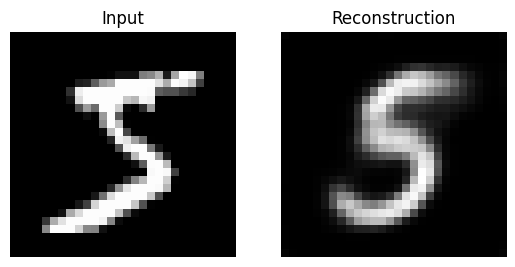

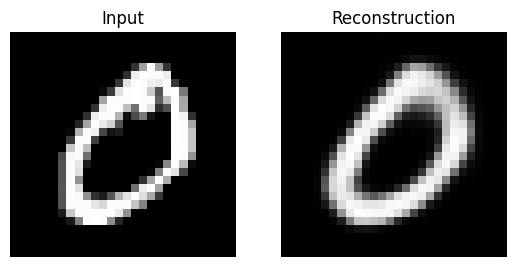

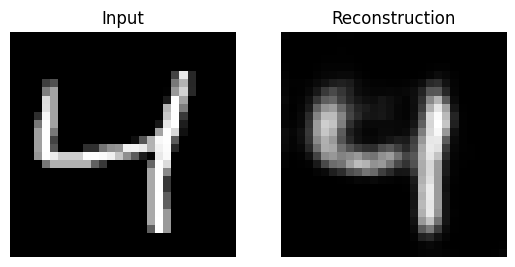

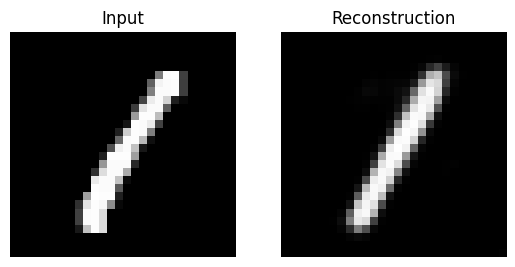

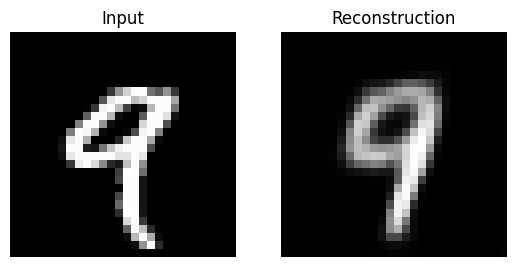

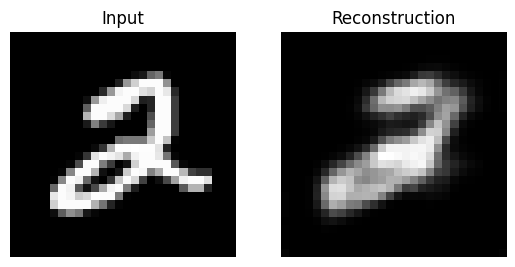

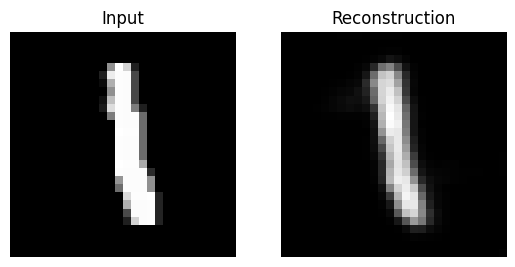

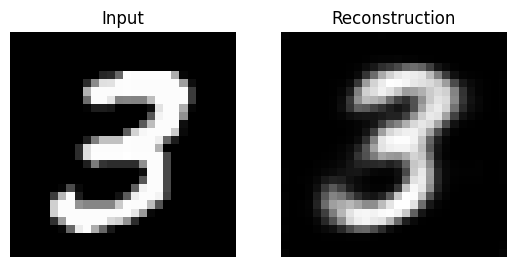

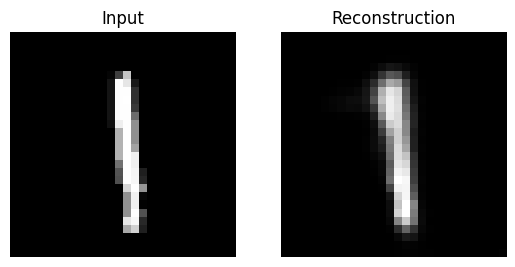

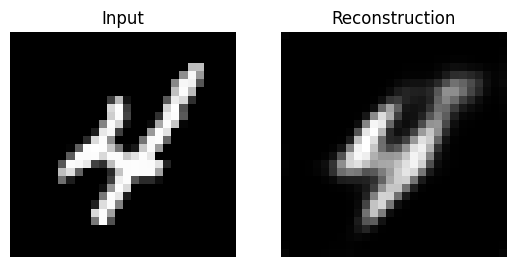

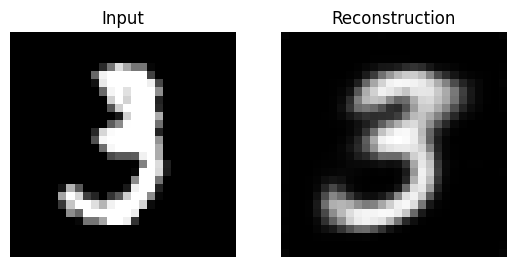

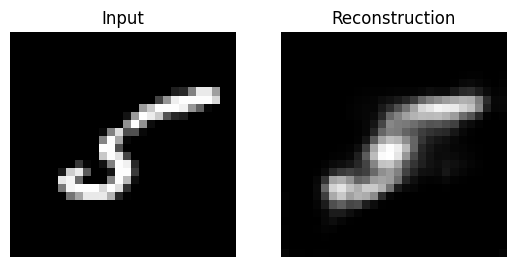

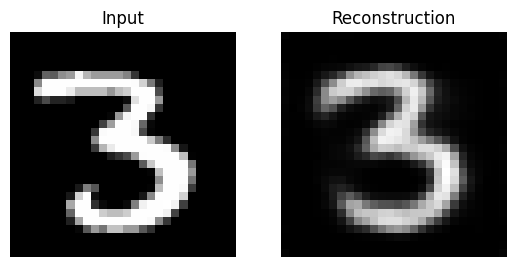

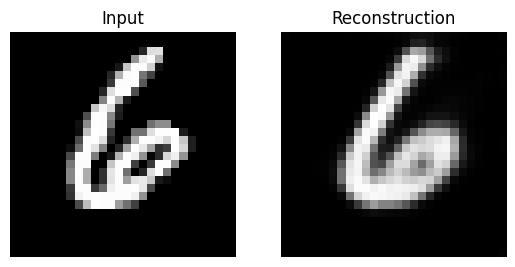

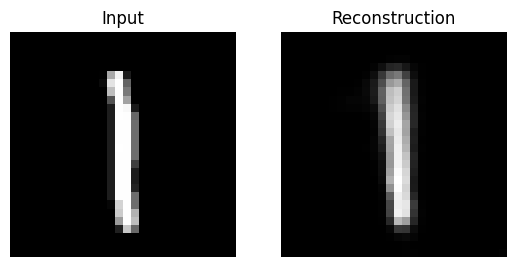

In [33]:
#quick check

with torch.no_grad():
    for i in range(15):
        x, _ = ds[i]
        x = x.unsqueeze(0).to(device)
        y = net(x)
        plt.subplot(1,2,1)
        plt.imshow(x.cpu().squeeze(), cmap='gray')
        plt.title("Input"); plt.axis('off')

        plt.subplot(1,2,2)
        plt.imshow(y.cpu().squeeze(), cmap='gray')
        plt.title("Reconstruction"); plt.axis('off')
        plt.show()



# C. Plot the latent space

In [34]:
# Here are 10 colours you can use. But feel free to use others, too.
colour_options = ['k', 'tab:brown', 'r', 'orange', 'gold', 'lawngreen', 'forestgreen', 'blue', 'mediumpurple', 'gray']

In [35]:
# Compute the latent-space representation for all the samples.

net.eval()
lat_list, lab_list = [], []
all_dl = torch.utils.data.DataLoader(ds, batch_size=256, shuffle=False)

with torch.no_grad():
    for x, y in all_dl:
        x = x.to(device)
        h = net.encode(x).cpu()
        lat_list.append(h)
        lab_list.append(y)

H = torch.cat(lat_list).numpy()
Y = torch.cat(lab_list).numpy()


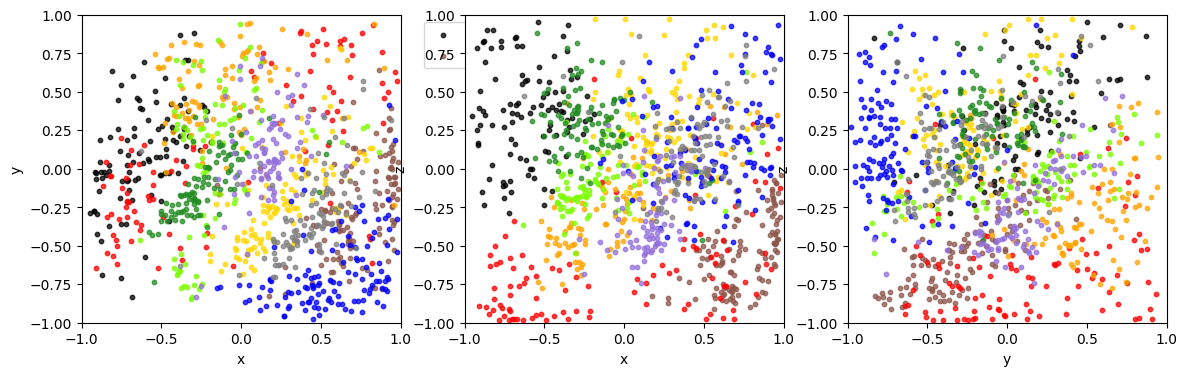

In [36]:
# You can create three 2D planar projections.

pairs = [('x','y',0,1), ('x','z',0,2), ('y','z',1,2)]
fig, axes = plt.subplots(1, 3, figsize=(14,4))

for ax, (lx, ly, i, j) in zip(axes, pairs):
    for k in range(10):
        m = (Y == k)
        ax.scatter(H[m,i], H[m,j], s=10, alpha=0.75,
                   c=colour_options[k], label=str(k))
    ax.set_xlim(-1,1)
    ax.set_ylim(-1,1)
    ax.set_xlabel(lx)
    ax.set_ylabel(ly)

axes[0].legend(ncol=5, bbox_to_anchor=(1.05,1.0), loc='upper left')
plt.show()

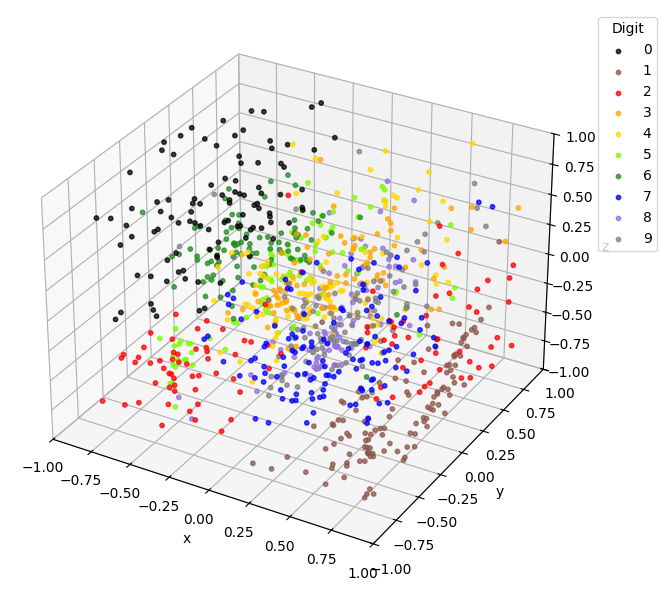

In [37]:
# Or you can plot a 3D scatter plot.
fig = plt.figure(figsize=(7,6))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(...)
#===== YOUR CODE HERE =====
for k in range(10):
    m = (Y == k)
    ax.scatter(H[m,0], H[m,1], H[m,2],
               s=10, alpha=0.75,
               c=colour_options[k],
               label=str(k))

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_zlim(-1, 1)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

ax.legend(title='Digit', loc='upper left', bbox_to_anchor=(1.02,1.0))
plt.tight_layout()
plt.show()

# D. Plot reconstructed digit images

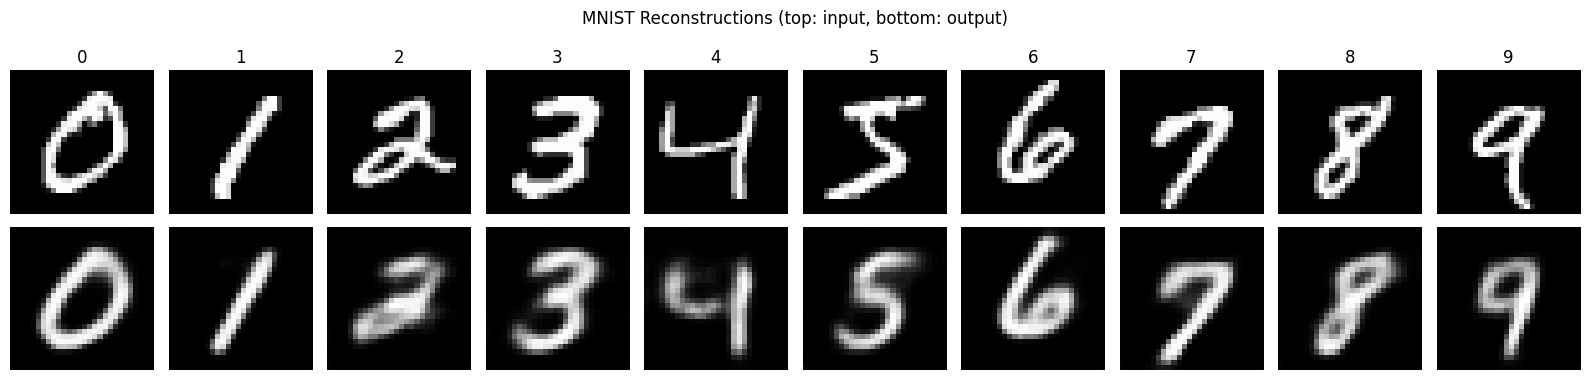

In [38]:
net.eval()

idx = [-1]*10
for i in range(len(ds)):
    y = int(ds[i][1])
    if idx[y] == -1:
        idx[y] = i
    if all(j != -1 for j in idx):
        break

x_batch = torch.stack([ds[i][0] for i in idx]).to(device)
with torch.no_grad():
    y_batch = net(x_batch)

# plot: top = inputs, bottom = reconstructions
fig, axes = plt.subplots(2, 10, figsize=(16,4))
for k in range(10):
    axes[0, k].imshow(x_batch[k].cpu().squeeze(), cmap='gray')
    axes[0, k].set_title(str(k)); axes[0, k].axis('off')

    axes[1, k].imshow(y_batch[k].cpu().squeeze(), cmap='gray')
    axes[1, k].axis('off')

plt.suptitle("MNIST Reconstructions (top: input, bottom: output)")
plt.tight_layout()
plt.show()

Digit Reconstructions

